In [1]:
import os
folder = "results/"
os.path.exists(folder)

True

In [2]:
import pandas as pd
import json

def load_results(filename):
    """Loads the results file and normalizes the metrics."""
    with open(filename, 'r') as f:
        data = json.load(f)
    
    df = pd.DataFrame(data)
    
    # Normalize metrics: Extract 'exact_match' or 'em'
    if 'metrics' in df.columns:
        # Check one row to see which key exists
        sample_metric = df['metrics'].iloc[0]
        metric_key = 'exact_match' if 'exact_match' in sample_metric else 'em'
        
        df['exact_match'] = df['metrics'].apply(lambda x: x.get(metric_key, 0))
        df['f1'] = df['metrics'].apply(lambda x: x.get('f1_score', x.get('f1', 0)))
    if "parsed_answer" in df.columns:
        df["prediction"] = df["parsed_answer"] 
        
    return df[['id', 'question', 'exact_match', 'prediction', 'gold_answers']]

# File paths (update these if your paths are different)
base_file = folder + 'qwen_base_closedbook_full_results.json'
sft_file = folder + 'qwen_sft_closedbook_full_results.json'
cot_file = folder + 'qwen_ftcot_closedbook_full_results_1.json'

# Load dataframes
print("Loading files...")
try:
    df_base = load_results(base_file)
    df_sft = load_results(sft_file)
    df_cot = load_results(cot_file)
except FileNotFoundError as e:
    print(f"Error: {e}. Please ensure the JSON files are in the current directory.")
    exit()

# Rename columns for merging
df_base = df_base.rename(columns={'exact_match': 'base_em', 'prediction': 'base_pred'})
df_sft = df_sft.rename(columns={'exact_match': 'sft_em', 'prediction': 'sft_pred'})
df_cot = df_cot.rename(columns={'exact_match': 'cot_em', 'prediction': 'cot_pred'})

# Merge DataFrames on 'id'
# We use inner join to ensure we only compare questions present in all files
merged = df_base[['id', 'question', 'base_em', 'base_pred']].merge(
    df_sft[['id', 'sft_em', 'sft_pred']], on='id'
).merge(
    df_cot[['id', 'cot_em', 'cot_pred']], on='id'
)

print(f"Successfully aligned {len(merged)} questions across all models.")

# --- Analysis ---

# 1. Overall Performance
print("\n--- Overall Accuracy (Exact Match) ---")
print(f"Base Model: {merged['base_em'].mean():.2%}")
print(f"SFT Model:  {merged['sft_em'].mean():.2%}")
print(f"CoT Model:  {merged['cot_em'].mean():.2%}")

# 2. Corrections (Wrong -> Right)
# How many did the specific model get RIGHT that the Base model got WRONG?
sft_fixed = merged[(merged['base_em'] == 0) & (merged['sft_em'] == 1)]
cot_fixed = merged[(merged['base_em'] == 0) & (merged['cot_em'] == 1)]

print("\n--- Improvement Analysis (Correcting Base Model Errors) ---")
print(f"SFT corrected {len(sft_fixed)} questions that Base got wrong.")
print(f"CoT corrected {len(cot_fixed)} questions that Base got wrong.")

# 3. Regressions (Right -> Wrong)
# How many did the specific model get WRONG that the Base model got RIGHT?
sft_broke = merged[(merged['base_em'] == 1) & (merged['sft_em'] == 0)]
cot_broke = merged[(merged['base_em'] == 1) & (merged['cot_em'] == 0)]

print("\n--- Regression Analysis (Breaking Correct Base Answers) ---")
print(f"SFT broke {len(sft_broke)} questions that Base originally got right.")
print(f"CoT broke {len(cot_broke)} questions that Base originally got right.")

# Optional: Export the improvements to inspect them
sft_fixed.to_csv('sft_improvements.csv', index=False)
cot_fixed.to_csv('cot_improvements.csv', index=False)

sft_broke.to_csv('sft_broke.csv', index=False)
cot_broke.to_csv('cot_broke.csv', index=False)

Loading files...
Successfully aligned 7405 questions across all models.

--- Overall Accuracy (Exact Match) ---
Base Model: 18.87%
SFT Model:  21.94%
CoT Model:  24.31%

--- Improvement Analysis (Correcting Base Model Errors) ---
SFT corrected 477 questions that Base got wrong.
CoT corrected 697 questions that Base got wrong.

--- Regression Analysis (Breaking Correct Base Answers) ---
SFT broke 249 questions that Base originally got right.
CoT broke 294 questions that Base originally got right.


In [3]:
print("Loading files...")
try:
    df_sft = load_results(sft_file)
    df_cot = load_results(cot_file)
except FileNotFoundError as e:
    print(f"Error: {e}. Please ensure the JSON files are in the current directory.")
    exit()

# Rename columns for distinct merging
df_sft = df_sft.rename(columns={'exact_match': 'sft_em', 'prediction': 'sft_pred'})
df_cot = df_cot.rename(columns={'exact_match': 'cot_em', 'prediction': 'cot_pred'})

# Merge SFT and CoT DataFrames on 'id'
merged = df_sft[['id', 'question', 'sft_em', 'sft_pred', 'gold_answers']].merge(
    df_cot[['id', 'cot_em', 'cot_pred']], on='id'
)

print(f"Successfully aligned {len(merged)} questions between SFT and CoT.")

# --- Analysis: Finetune CoT vs Normal Finetune (SFT) ---

# 1. Overall Accuracy Comparison
print("\n--- Overall Accuracy (Exact Match) ---")
print(f"SFT Model: {merged['sft_em'].mean():.2%}")
print(f"CoT Model: {merged['cot_em'].mean():.2%}")

# 2. CoT Improvements (SFT Wrong -> CoT Right)
cot_wins = merged[(merged['sft_em'] == 0) & (merged['cot_em'] == 1)]

# 3. SFT Wins (SFT Right -> CoT Wrong)
sft_wins = merged[(merged['sft_em'] == 1) & (merged['cot_em'] == 0)]

# 4. Agreements
both_correct = merged[(merged['sft_em'] == 1) & (merged['cot_em'] == 1)]
both_wrong = merged[(merged['sft_em'] == 0) & (merged['cot_em'] == 0)]

print("\n--- Head-to-Head Comparison ---")
print(f"CoT Corrected (SFT Wrong -> CoT Right): {len(cot_wins)}")
print(f"SFT Prevailed (SFT Right -> CoT Wrong): {len(sft_wins)}")
print(f"Both Correct: {len(both_correct)}")
print(f"Both Wrong:   {len(both_wrong)}")

# Optional: Export the differences to CSV for manual inspection
if len(cot_wins) > 0:
    cot_wins.to_csv('cot_improvements_over_sft.csv', index=False)
    print("\nSaved 'cot_improvements_over_sft.csv'")

if len(sft_wins) > 0:
    sft_wins.to_csv('sft_wins_over_cot.csv', index=False)
    print("Saved 'sft_wins_over_cot.csv'")

Loading files...
Successfully aligned 7405 questions between SFT and CoT.

--- Overall Accuracy (Exact Match) ---
SFT Model: 21.94%
CoT Model: 24.31%

--- Head-to-Head Comparison ---
CoT Corrected (SFT Wrong -> CoT Right): 556
SFT Prevailed (SFT Right -> CoT Wrong): 381
Both Correct: 1244
Both Wrong:   5224

Saved 'cot_improvements_over_sft.csv'
Saved 'sft_wins_over_cot.csv'


In [4]:
sft_broke.head()

,id,question,base_em,base_pred,sft_em,sft_pred,cot_em,cot_pred
40,5a7a0e1e5542990783324e1a,Which dog's ancestors include Gordon and Irish...,1.0,Scotch Collie,0.0,Manchester Terrier,1.0,Scotch Collie
67,5ae7ba7a5542993210983f12,What is the name of the singer who's song was ...,1.0,Usher,0.0,Rihanna,0.0,Aerosmith
78,5a78bd9b554299078472774a,What nationality were social anthropologists A...,1.0,British,0.0,English,1.0,British
79,5a7625e8554299109176e66a,In which year was the King who made the 1925 B...,1.0,1865,0.0,1934,1.0,1865
89,5aba749055429901930fa7d8,What occupation do Chris Menges and Aram Avaki...,1.0,Director,0.0,film director,0.0,film director


In [5]:
import pandas as pd
import json

def load_results(filename, model_prefix):
    """Loads results and normalizes EM and Abstention columns."""
    with open(filename, 'r') as f:
        data = json.load(f)
    df = pd.DataFrame(data)
    
    # 1. Normalize Exact Match (EM)
    if 'metrics' in df.columns:
        # Check first row to see if key is 'exact_match' or 'em'
        sample_metric = df['metrics'].iloc[0]
        metric_key = 'exact_match' if 'exact_match' in sample_metric else 'em'
        df[f'{model_prefix}_em'] = df['metrics'].apply(lambda x: x.get(metric_key, 0))
    
    # 2. Normalize Abstention
    # If the file doesn't have 'is_abstention', assume False (it never abstains)
    if 'is_abstention' in df.columns:
        df[f'{model_prefix}_abstain'] = df['is_abstention']
    else:
        df[f'{model_prefix}_abstain'] = False
        
    return df[['id', f'{model_prefix}_em', f'{model_prefix}_abstain']]

# --- File Paths ---
# Replace 'qwen_new_model.json' with your actual new model filename
files = {
    'base': folder + 'qwen_base_closedbook_full_results.json',
    'sft': folder + 'qwen_sft_closedbook_full_results.json',
    'cot': folder + 'qwen_ftcot_closedbook_full_results_1.json',
    'new': folder + 'eval_results_hotpotqa-abstention-80-20_SHORT_lr0.0002_bs4_20251210_020244.json' 
}

# --- Load and Merge ---
print("Loading files...")
dfs = []
try:
    for prefix, fname in files.items():
        dfs.append(load_results(fname, prefix))
except FileNotFoundError as e:
    print(f"Error: {e}")
    exit()

# Merge all dataframes on 'id'
merged = dfs[0]
for df in dfs[1:]:
    merged = merged.merge(df, on='id')

print(f"Aligned {len(merged)} questions across all models.")

# --- Analysis Function ---
def calculate_abstention_stats(df, ref_model):
    """
    Calculates Precision and Recall of abstention assuming 
    'Ref Model Wrong' is the ground truth for 'Should Abstain'.
    """
    # TP: Ref is Wrong (Should Abstain) AND New Model Abstained
    tp = len(df[(df[f'{ref_model}_em'] == 0) & (df['new_abstain'] == True)])
    
    # FP: Ref is Right (Should Answer) BUT New Model Abstained
    fp = len(df[(df[f'{ref_model}_em'] == 1) & (df['new_abstain'] == True)])
    
    # FN: Ref is Wrong (Should Abstain) BUT New Model Answered
    fn = len(df[(df[f'{ref_model}_em'] == 0) & (df['new_abstain'] == False)])
    
    # Precision: TP / (TP + FP)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    
    # Recall: TP / (TP + FN)
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    
    return {
        'Reference Model': ref_model.upper(),
        'Precision': f"{precision:.2%}",
        'Recall': f"{recall:.2%}",
        'TP (Good Abstain)': tp,
        'FP (Bad Abstain)': fp,
        'FN (Missed Abstain)': fn
    }

# --- Run Analysis ---
stats = []
stats.append(calculate_abstention_stats(merged, 'base'))
stats.append(calculate_abstention_stats(merged, 'sft'))
stats.append(calculate_abstention_stats(merged, 'cot'))

# Bonus: Intersection of Failures (Hardest Questions)
# Define "Hardest" as: Base Wrong AND SFT Wrong AND CoT Wrong
merged['all_others_wrong'] = (
    (merged['base_em'] == 0) & 
    (merged['sft_em'] == 0) & 
    (merged['cot_em'] == 0)
).astype(int)

# Create a temporary column to map "all_others_wrong=1" to "em=0" logic for the function
merged['hardest_em'] = 1 - merged['all_others_wrong']
stats.append(calculate_abstention_stats(merged, 'hardest'))

# Display Results
results_df = pd.DataFrame(stats)
print("\n--- Abstention Analysis (New Model) ---")
print(results_df.to_string(index=False))

# Optional: Save breakdown
results_df.to_csv('abstention_analysis.csv', index=False)

Loading files...
Aligned 7405 questions across all models.

--- Abstention Analysis (New Model) ---
Reference Model Precision Recall  TP (Good Abstain)  FP (Bad Abstain)  FN (Missed Abstain)
           BASE    97.49% 55.69%               3346                86                 2662
            SFT    95.72% 56.83%               3285               147                 2495
            COT    93.97% 57.54%               3225               207                 2380
        HARDEST    90.53% 60.85%               3107               325                 1999


Loading files...
Aligned 7405 questions across all models.
Confusion matrices with metrics saved to 'abstention_confusion_matrices_large.png'


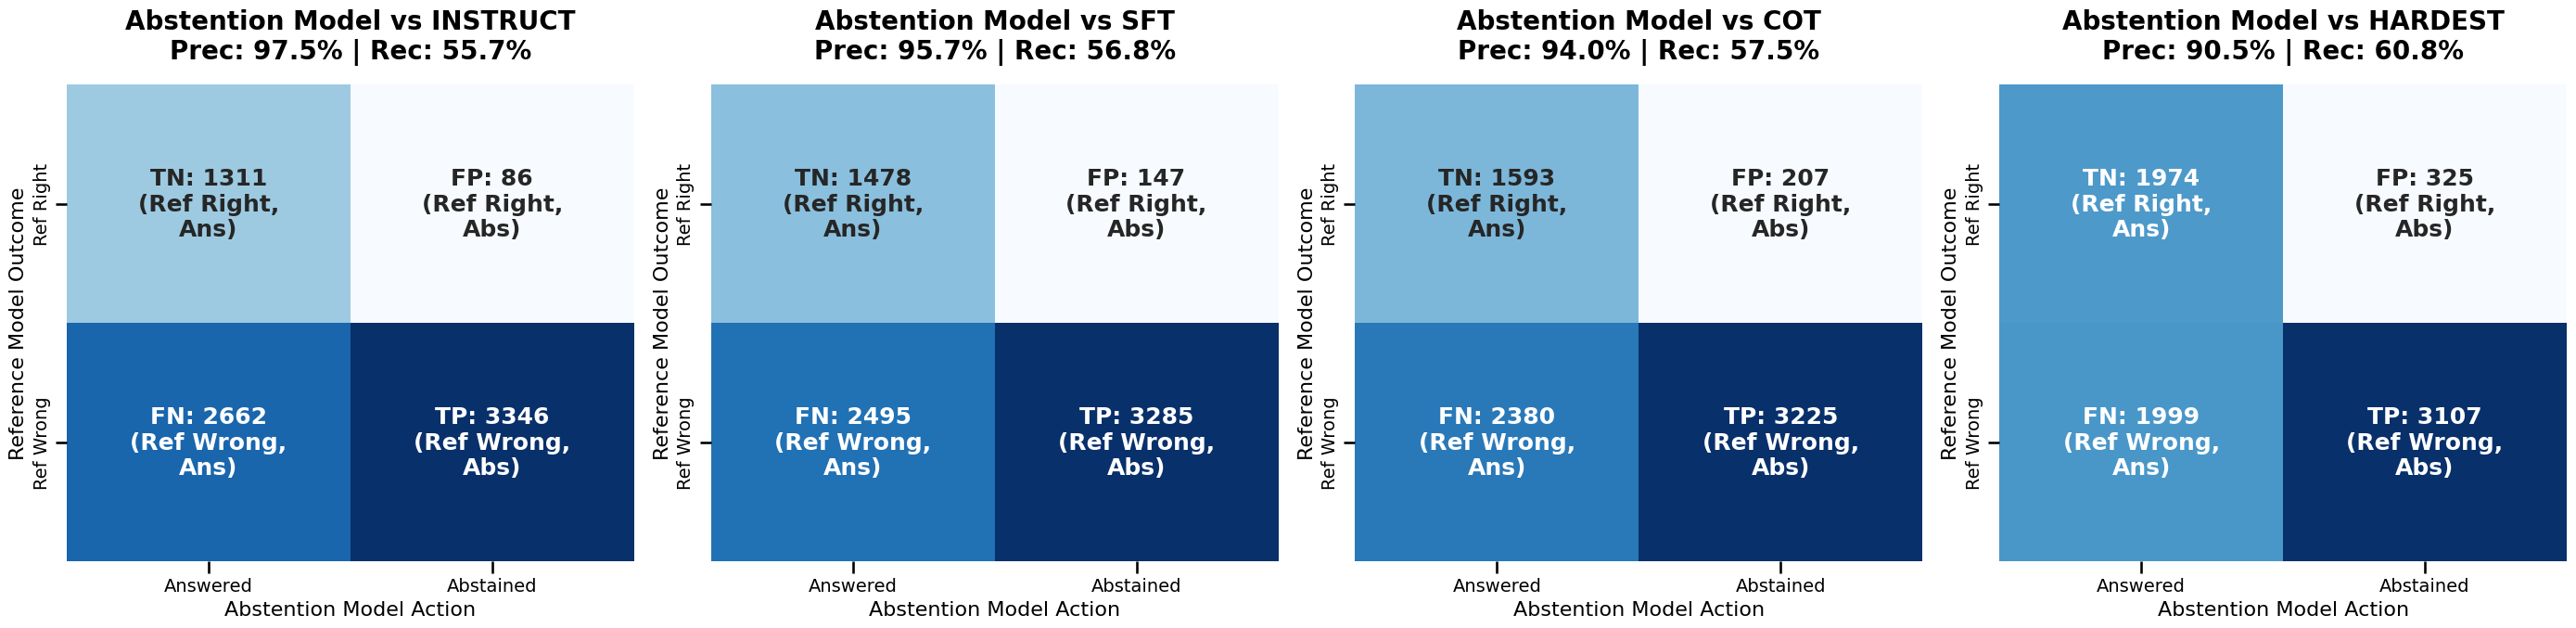

In [11]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# --- Configuration ---
# Set global font scale for better readability
sns.set_context("talk", font_scale=1.1)
plt.rcParams.update({'font.size': 14})

def load_results(filename, model_prefix):
    """Loads results and normalizes EM and Abstention columns."""
    with open(filename, 'r') as f:
        data = json.load(f)
    df = pd.DataFrame(data)
    
    # 1. Normalize Exact Match (EM)
    if 'metrics' in df.columns:
        # Check first row to see if key is 'exact_match' or 'em'
        sample_metric = df['metrics'].iloc[0]
        metric_key = 'exact_match' if 'exact_match' in sample_metric else 'em'
        df[f'{model_prefix}_em'] = df['metrics'].apply(lambda x: x.get(metric_key, 0))
    
    # 2. Normalize Abstention
    if 'is_abstention' in df.columns:
        df[f'{model_prefix}_abstain'] = df['is_abstention']
    else:
        df[f'{model_prefix}_abstain'] = False
        
    return df[['id', f'{model_prefix}_em', f'{model_prefix}_abstain']]

# --- File Paths ---
# folder = './' # Ensure this is defined
files = {
    'instruct': folder + 'qwen_base_closedbook_full_results.json', # Renamed key to 'instruct'
    'sft': folder + 'qwen_sft_closedbook_full_results.json',
    'cot': folder + 'qwen_ftcot_closedbook_full_results_1.json',
    'new': folder + 'eval_results_hotpotqa-abstention-80-20_SHORT_lr0.0002_bs4_20251210_020244.json' 
}

# --- Load and Merge ---
print("Loading files...")
dfs = []
try:
    for prefix, fname in files.items():
        dfs.append(load_results(fname, prefix))
except FileNotFoundError as e:
    print(f"Error: {e}")
    exit()

merged = dfs[0]
for df in dfs[1:]:
    merged = merged.merge(df, on='id')

print(f"Aligned {len(merged)} questions across all models.")

# --- Confusion Matrix Visualization ---

# Define Comparisons (Updated 'base' -> 'instruct')
comparisons = ['instruct', 'sft', 'cot', 'hardest']

# Calculate "Hardest" (All reference models wrong)
# Updated column name from 'base_em' to 'instruct_em'
merged['all_others_wrong'] = (
    (merged['instruct_em'] == 0) & 
    (merged['sft_em'] == 0) & 
    (merged['cot_em'] == 0)
).astype(int)

# Set up the plot area
fig, axes = plt.subplots(1, 4, figsize=(28, 7))

for i, ref in enumerate(comparisons):
    # 1. Define "Ground Truth" for Abstention
    # "Positive" (1) = We SHOULD Abstain (because Ref model is Wrong)
    # "Negative" (0) = We SHOULD Answer (because Ref model is Right)
    if ref == 'hardest':
        y_true = merged['all_others_wrong'] # 1 if all wrong
    else:
        y_true = 1 - merged[f'{ref}_em']    # 1 if wrong, 0 if right
        
    # 2. Define Prediction
    # "Positive" (1) = Model Abstained
    # "Negative" (0) = Model Answered
    y_pred = merged['new_abstain'].astype(int)
    
    # 3. Compute Matrix
    # Labels: [0, 1] -> [Should Answer, Should Abstain]
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    
    # 4. Calculate Precision and Recall
    tn, fp, fn, tp = cm.ravel()
    
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    
    # 5. Create Custom Annotations (Large Text)
    annot_text = [
        f"TN: {tn}\n(Ref Right,\nAns)",     f"FP: {fp}\n(Ref Right,\nAbs)",
        f"FN: {fn}\n(Ref Wrong,\nAns)",     f"TP: {tp}\n(Ref Wrong,\nAbs)"
    ]
    annot_text = np.array(annot_text).reshape(2, 2)
    
    # 6. Plot Heatmap
    sns.heatmap(cm, annot=annot_text, fmt='', ax=axes[i], cmap='Blues', cbar=False,
                annot_kws={"size": 18, "weight": "bold"},
                xticklabels=['Answered', 'Abstained'],
                yticklabels=['Ref Right', 'Ref Wrong'])
    
    # 7. Titles and Labels
    title_text = f"Abstention Model vs {ref.upper()}\nPrec: {precision:.1%} | Rec: {recall:.1%}"
    axes[i].set_title(title_text, fontsize=20, pad=20, fontweight='bold')
    axes[i].set_xlabel("Abstention Model Action", fontsize=16)
    axes[i].set_ylabel("Reference Model Outcome", fontsize=16)
    
    # Tick Label Size
    axes[i].tick_params(axis='both', which='major', labelsize=14)

plt.tight_layout()
output_filename = 'abstention_confusion_matrices_large.png'
plt.savefig(output_filename)
print(f"Confusion matrices with metrics saved to '{output_filename}'")
plt.show()

In [9]:
import json
import numpy as np
import os
import pandas as pd
from datasets import load_dataset
from collections import defaultdict

# --- Configuration ---
FOLDER = './results/'  # Ensure your JSON files are here
DATASET_NAME = "hotpot_qa"
SUBSET_NAME = "distractor"
SPLIT = "validation"
OUTPUT_FOLDER = "breakdown"
OUTPUT_FILENAME = "all_models_type_breakdown_selective.json" 

# File definitions
FILES = {
    'instruct':      FOLDER + 'qwen_base_closedbook_full_results.json',
    'sft':           FOLDER + 'qwen_sft_closedbook_full_results.json',
    'cot':           FOLDER + 'qwen_ftcot_closedbook_full_results_1.json',
    'abstention sft': FOLDER + 'eval_results_hotpotqa-abstention-80-20_SHORT_lr0.0002_bs4_20251210_020244.json'
}

def get_metric_safe(item, metric_name):
    """
    Safely retrieves a metric (em/f1) from the item dict.
    Handles differences in key names (e.g., 'exact_match' vs 'em').
    """
    metrics = item.get('metrics', {})
    keys = metrics.keys()
    
    # EM Logic
    if metric_name == 'em':
        if 'exact_match' in keys: return metrics['exact_match']
        if 'em' in keys: return metrics['em']
        if 'EM' in keys: return metrics['EM']
    
    # F1 Logic
    if metric_name == 'f1':
        if 'f1_score' in keys: return metrics['f1_score']
        if 'f1' in keys: return metrics['f1']
        if 'F1' in keys: return metrics['F1']
        
    return 0.0

def main():
    # 1. Load Original Dataset for Type Mapping
    print(f"Loading original dataset ({DATASET_NAME}/{SUBSET_NAME}/{SPLIT}) to retrieve question types...")
    dataset = load_dataset(DATASET_NAME, SUBSET_NAME, split=SPLIT)
    
    # Map ID -> Type (comparison / bridge)
    id_to_type = {item['id']: item['type'] for item in dataset}
    
    # Container for all results
    final_breakdown = {}

    # 2. Process Each Model
    print(f"\nProcessing {len(FILES)} models...")
    
    for model_name, file_path in FILES.items():
        print(f"  -> Processing: {model_name}...")
        
        if not os.path.exists(file_path):
            print(f"     [WARNING] File not found: {file_path}. Skipping.")
            continue
            
        with open(file_path, 'r', encoding='utf-8') as f:
            results = json.load(f)
            
        # Buckets for this model
        # Structure: {'comparison': {'all_em': [], 'sel_em': [], ...}}
        metrics_by_type = defaultdict(lambda: {
            'all_em': [], 'all_f1': [], 
            'sel_em': [], 'sel_f1': []
        })
        
        missing_ids = 0
        
        for item in results:
            uid = item.get('id')
            
            if uid in id_to_type:
                q_type = id_to_type[uid]
                
                em = get_metric_safe(item, 'em')
                f1 = get_metric_safe(item, 'f1')
                is_abs = item.get('is_abstention', False)
                
                # Standard Metrics (All samples)
                metrics_by_type[q_type]['all_em'].append(em)
                metrics_by_type[q_type]['all_f1'].append(f1)
                
                # Selective Metrics (Only if NOT abstained)
                if not is_abs:
                    metrics_by_type[q_type]['sel_em'].append(em)
                    metrics_by_type[q_type]['sel_f1'].append(f1)
            else:
                missing_ids += 1

        if missing_ids > 0:
            print(f"     (Note: {missing_ids} IDs were missing from dataset map)")

        # Aggregate stats for this model
        model_stats = {}
        order = ['comparison', 'bridge'] 
        
        # Helper to calculate mean percentage
        def calc_mean_pct(data_list):
            return round(np.mean(data_list) * 100, 2) if data_list else 0.0

        # Per-Type Stats
        for q_type in order:
            if q_type in metrics_by_type:
                d = metrics_by_type[q_type]
                model_stats[q_type] = {
                    "count": len(d['all_em']),
                    "em": calc_mean_pct(d['all_em']),
                    "f1": calc_mean_pct(d['all_f1']),
                    "sel_count": len(d['sel_em']),
                    "sel_em": calc_mean_pct(d['sel_em']),
                    "sel_f1": calc_mean_pct(d['sel_f1'])
                }
        
        # Overall Stats
        all_em = [x for t in metrics_by_type for x in metrics_by_type[t]['all_em']]
        all_f1 = [x for t in metrics_by_type for x in metrics_by_type[t]['all_f1']]
        sel_em = [x for t in metrics_by_type for x in metrics_by_type[t]['sel_em']]
        sel_f1 = [x for t in metrics_by_type for x in metrics_by_type[t]['sel_f1']]
        
        model_stats['overall'] = {
            "count": len(all_em),
            "em": calc_mean_pct(all_em),
            "f1": calc_mean_pct(all_f1),
            "sel_count": len(sel_em),
            "sel_em": calc_mean_pct(sel_em),
            "sel_f1": calc_mean_pct(sel_f1)
        }
        
        final_breakdown[model_name] = model_stats

    # 3. Print Comparison Table
    print("\n" + "="*115)
    print(f"{'METRIC BREAKDOWN ACROSS MODELS & QUESTION TYPES (With Selective Scores)':^115}")
    print("="*115)
    
    # Headers
    # Sel. = Selective
    print(f"{'Model':<16} | {'Type':<10} | {'Cnt':<5} | {'EM':<6} | {'F1':<6} | {'Sel.Cnt':<7} | {'Sel.EM':<8} | {'Sel.F1':<8}")
    print("-" * 115)

    for model_name, stats in final_breakdown.items():
        for q_type in ['comparison', 'bridge', 'overall']:
            if q_type in stats:
                d = stats[q_type]
                
                # Formatting
                prefix = model_name if q_type == 'comparison' else "" 
                
                if q_type == 'overall':
                    print(f"{'':<16} | {'-------':<10} | {'-----':<5} | {'------':<6} | {'------':<6} | {'-------':<7} | {'--------':<8} | {'--------':<8}")
                    type_display = "OVERALL"
                else:
                    type_display = q_type.capitalize()
                
                # Only show selective scores if they differ from standard counts (or if it's the abstention model)
                # If Sel.Cnt == Cnt, it means no abstention happened (standard models), so we can print "-" or the same score.
                # Here we print "-" for clarity if Sel.Cnt == Cnt to highlight the abstention model.
                
                if d['sel_count'] == d['count']:
                    sel_cnt_str, sel_em_str, sel_f1_str = "-", "-", "-"
                else:
                    sel_cnt_str = str(d['sel_count'])
                    sel_em_str = f"{d['sel_em']:.2f}"
                    sel_f1_str = f"{d['sel_f1']:.2f}"

                print(f"{prefix:<16} | {type_display:<10} | {d['count']:<5} | {d['em']:<6.2f} | {d['f1']:<6.2f} | {sel_cnt_str:<7} | {sel_em_str:<8} | {sel_f1_str:<8}")
        print("-" * 115)

    # 4. Save to JSON
    if not os.path.exists(OUTPUT_FOLDER):
        os.makedirs(OUTPUT_FOLDER)
        
    output_path = os.path.join(OUTPUT_FOLDER, OUTPUT_FILENAME)
    
    with open(output_path, 'w', encoding='utf-8') as f:
        json.dump(final_breakdown, f, indent=2)
        
    print(f"\nFull breakdown saved to: {output_path}")

if __name__ == "__main__":
    main()

Loading original dataset (hotpot_qa/distractor/validation) to retrieve question types...

Processing 4 models...
  -> Processing: instruct...
  -> Processing: sft...
  -> Processing: cot...
  -> Processing: abstention sft...

                      METRIC BREAKDOWN ACROSS MODELS & QUESTION TYPES (With Selective Scores)                      
Model            | Type       | Cnt   | EM     | F1     | Sel.Cnt | Sel.EM   | Sel.F1  
-------------------------------------------------------------------------------------------------------------------
instruct         | Comparison | 1487  | 53.26  | 61.05  | -       | -        | -       
                 | Bridge     | 5918  | 10.22  | 18.48  | -       | -        | -       
                 | -------    | ----- | ------ | ------ | ------- | -------- | --------
                 | OVERALL    | 7405  | 18.87  | 27.03  | -       | -        | -       
------------------------------------------------------------------------------------------------------

In [ ]:
import json
import numpy as np
import os
from datasets import load_dataset
from collections import defaultdict

# --- Configuration ---
# Update this to the folder where your tinker json files are located
FOLDER = './' 
DATASET_NAME = "hotpot_qa"
SUBSET_NAME = "distractor"
SPLIT = "validation"
OUTPUT_FOLDER = "breakdown"
OUTPUT_FILENAME = "tinker_models_type_breakdown.json"

# File definitions
FILES = {
    'Tinker CoT':       os.path.join(FOLDER, 'tinker_cot_results.json'),
    'Tinker SFT':       os.path.join(FOLDER, 'tinker_eval_results.json'),
    'Tinker Vanilla':   os.path.join(FOLDER, 'tinker_vanilla_results.json'),
    'Tinker Abstention': os.path.join(FOLDER, 'tinker_abstention_results.json')
}

def get_metric_safe(item, metric_name):
    """
    Safely retrieves a metric (em/f1) from the item dict.
    Handles differences in key names (e.g., 'exact_match' vs 'em').
    """
    metrics = item.get('metrics', {})
    keys = metrics.keys()
    
    # EM Logic
    if metric_name == 'em':
        if 'exact_match' in keys: return metrics['exact_match']
        if 'em' in keys: return metrics['em']
        if 'EM' in keys: return metrics['EM']
    
    # F1 Logic
    if metric_name == 'f1':
        if 'f1_score' in keys: return metrics['f1_score']
        if 'f1' in keys: return metrics['f1']
        if 'F1' in keys: return metrics['F1']
        
    return 0.0

def normalize_text(text):
    """Simple normalization to help match text across files."""
    if not isinstance(text, str): return ""
    return text.strip()

def main():
    # 1. Load Original Dataset for Type Mapping
    print(f"Loading original dataset ({DATASET_NAME}/{SUBSET_NAME}/{SPLIT})...")
    dataset = load_dataset(DATASET_NAME, SUBSET_NAME, split=SPLIT)
    
    # Create TWO Maps:
    # 1. ID -> Type (For CoT, SFT, Vanilla)
    # 2. Text -> Type (For Abstention model which lacks ID)
    print("Building lookup maps...")
    id_to_type = {}
    text_to_type = {}
    
    for item in dataset:
        uid = item['id']
        q_text = normalize_text(item['question'])
        q_type = item['type'] # 'comparison' or 'bridge'
        
        id_to_type[uid] = q_type
        text_to_type[q_text] = q_type
    
    print(f"Maps built. {len(id_to_type)} IDs and {len(text_to_type)} unique questions indexed.")

    # Container for all results
    final_breakdown = {}

    # 2. Process Each Model
    print(f"\nProcessing {len(FILES)} models...")
    
    for model_name, file_path in FILES.items():
        print(f"  -> Processing: {model_name}...")
        
        if not os.path.exists(file_path):
            print(f"     [WARNING] File not found: {file_path}. Skipping.")
            continue
            
        with open(file_path, 'r', encoding='utf-8') as f:
            results = json.load(f)
            
        # Buckets for this model
        metrics_by_type = defaultdict(lambda: {
            'all_em': [], 'all_f1': [], 
            'sel_em': [], 'sel_f1': []
        })
        
        match_count = 0
        missing_count = 0
        
        for item in results:
            q_type = None
            
            # STRATEGY 1: Try ID Lookup (Preferred)
            if 'id' in item and item['id'] in id_to_type:
                q_type = id_to_type[item['id']]
                
            # STRATEGY 2: Try Text Lookup (Fallback for Abstention file)
            elif 'question' in item:
                q_text = normalize_text(item['question'])
                if q_text in text_to_type:
                    q_type = text_to_type[q_text]
            
            # If we found the type, process the metrics
            if q_type:
                match_count += 1
                
                em = get_metric_safe(item, 'em')
                f1 = get_metric_safe(item, 'f1')
                is_abs = item.get('is_abstention', False)
                
                # Standard Metrics (All samples)
                metrics_by_type[q_type]['all_em'].append(em)
                metrics_by_type[q_type]['all_f1'].append(f1)
                
                # Selective Metrics (Only if NOT abstained)
                if not is_abs:
                    metrics_by_type[q_type]['sel_em'].append(em)
                    metrics_by_type[q_type]['sel_f1'].append(f1)
            else:
                missing_count += 1

        print(f"     Matched: {match_count} | Missing/Unmatched: {missing_count}")

        # Aggregate stats for this model
        model_stats = {}
        order = ['comparison', 'bridge'] 
        
        # Helper to calculate mean percentage
        def calc_mean_pct(data_list):
            return round(np.mean(data_list) * 100, 2) if data_list else 0.0

        # Per-Type Stats
        for q_type in order:
            if q_type in metrics_by_type:
                d = metrics_by_type[q_type]
                model_stats[q_type] = {
                    "count": len(d['all_em']),
                    "em": calc_mean_pct(d['all_em']),
                    "f1": calc_mean_pct(d['all_f1']),
                    "sel_count": len(d['sel_em']),
                    "sel_em": calc_mean_pct(d['sel_em']),
                    "sel_f1": calc_mean_pct(d['sel_f1'])
                }
        
        # Overall Stats
        all_em = [x for t in metrics_by_type for x in metrics_by_type[t]['all_em']]
        all_f1 = [x for t in metrics_by_type for x in metrics_by_type[t]['all_f1']]
        sel_em = [x for t in metrics_by_type for x in metrics_by_type[t]['sel_em']]
        sel_f1 = [x for t in metrics_by_type for x in metrics_by_type[t]['sel_f1']]
        
        model_stats['overall'] = {
            "count": len(all_em),
            "em": calc_mean_pct(all_em),
            "f1": calc_mean_pct(all_f1),
            "sel_count": len(sel_em),
            "sel_em": calc_mean_pct(sel_em),
            "sel_f1": calc_mean_pct(sel_f1)
        }
        
        final_breakdown[model_name] = model_stats

    # 3. Print Comparison Table
    print("\n" + "="*115)
    print(f"{'TINKER MODELS: METRIC BREAKDOWN BY QUESTION TYPE':^115}")
    print("="*115)
    
    # Headers
    print(f"{'Model':<18} | {'Type':<10} | {'Cnt':<5} | {'EM':<6} | {'F1':<6} | {'Sel.Cnt':<7} | {'Sel.EM':<8} | {'Sel.F1':<8}")
    print("-" * 115)

    for model_name, stats in final_breakdown.items():
        for q_type in ['comparison', 'bridge', 'overall']:
            if q_type in stats:
                d = stats[q_type]
                
                # Formatting
                prefix = model_name if q_type == 'comparison' else "" 
                
                if q_type == 'overall':
                    print(f"{'':<18} | {'-------':<10} | {'-----':<5} | {'------':<6} | {'------':<6} | {'-------':<7} | {'--------':<8} | {'--------':<8}")
                    type_display = "OVERALL"
                else:
                    type_display = q_type.capitalize()
                
                # Only show selective numbers if they are meaningful (different from total or it's the abstention model)
                # We show them for "Tinker Abstention" or if counts differ
                is_selective_model = (d['sel_count'] != d['count'])
                
                if is_selective_model:
                    sel_cnt_str = str(d['sel_count'])
                    sel_em_str = f"{d['sel_em']:.2f}"
                    sel_f1_str = f"{d['sel_f1']:.2f}"
                else:
                    sel_cnt_str, sel_em_str, sel_f1_str = "-", "-", "-"

                print(f"{prefix:<18} | {type_display:<10} | {d['count']:<5} | {d['em']:<6.2f} | {d['f1']:<6.2f} | {sel_cnt_str:<7} | {sel_em_str:<8} | {sel_f1_str:<8}")
        print("-" * 115)

    # 4. Save to JSON
    if not os.path.exists(OUTPUT_FOLDER):
        os.makedirs(OUTPUT_FOLDER)
        
    output_path = os.path.join(OUTPUT_FOLDER, OUTPUT_FILENAME)
    
    with open(output_path, 'w', encoding='utf-8') as f:
        json.dump(final_breakdown, f, indent=2)
        
    print(f"\nFull breakdown saved to: {output_path}")

if __name__ == "__main__":
    main()

In [12]:
import json

def analyze_reasoning_trace(base_file_path, cot_file_path):
    """
    Analyzes HotpotQA results to find cases where Base model failed and CoT model succeeded.
    """
    # 1. Load the data
    try:
        with open(base_file_path, 'r') as f:
            base_results = json.load(f)
        with open(cot_file_path, 'r') as f:
            cot_results = json.load(f)
    except FileNotFoundError as e:
        print(f"Error loading files: {e}")
        return

    # 2. Index Base results by ID for O(1) lookup
    base_map = {item['id']: item for item in base_results}
    
    print(f"Loaded {len(base_results)} base results and {len(cot_results)} CoT results.\n")
    print("--- Reasoning Trace Qualitative Check (Base: WRONG -> CoT: CORRECT) ---\n")

    found_count = 0

    # 3. Iterate through CoT results and compare
    for cot_item in cot_results:
        q_id = cot_item.get('id')
        
        # Ensure we have a matching base result
        if q_id not in base_map:
            continue
            
        base_item = base_map[q_id]

        # 4. Check Metrics (Handling different key names based on your snippets)
        # Base uses "exact_match", CoT uses "em"
        base_em = base_item.get('metrics', {}).get('exact_match', 0)
        cot_em = cot_item.get('metrics', {}).get('em', 0)

        # Condition: Base Model = Wrong (0.0) AND CoT Model = Correct (1.0)
        if base_em == 0.0 and cot_em == 1.0:
            found_count += 1
            
            # Extract relevant fields
            question = cot_item.get('question', 'N/A')
            base_pred = base_item.get('prediction', 'N/A')
            cot_pred = cot_item.get('parsed_answer', 'N/A')
            reasoning = cot_item.get('parsed_reasoning', cot_item.get('full_generation', 'N/A'))
            
            # Print Analysis Block
            print(f"Case #{found_count} (ID: {q_id})")
            print(f"Question: {question}")
            print(f"Base Model Prediction (Wrong): {base_pred}")
            print(f"CoT Model Prediction (Correct): {cot_pred}")
            print("-" * 20)
            print("Reasoning Trace:")
            print(reasoning)
            print("=" * 60 + "\n")

    print(f"Analysis complete. Found {found_count} cases satisfying criteria.")

# --- Execute Analysis ---
if __name__ == "__main__":
    # Update filenames if they are in a specific subdirectory
    folder = "results/"
    base_file = folder + 'qwen_base_closedbook_full_results.json'
    cot_file = folder + 'qwen_ftcot_closedbook_full_results_1.json'
    
    analyze_reasoning_trace(base_file, cot_file)

Loaded 7405 base results and 7405 CoT results.

--- Reasoning Trace Qualitative Check (Base: WRONG -> CoT: CORRECT) ---

Case #1 (ID: 5a8b57f25542995d1e6f1371)
Question: Were Scott Derrickson and Ed Wood of the same nationality?
Base Model Prediction (Wrong): No
CoT Model Prediction (Correct): yes
--------------------
Reasoning Trace:
Step 1: The question asks about the nationalities of Scott Derrickson and Ed Wood.  
Step 2: Scott Derrickson is an American film director, born in the United States, while Ed Wood was an American filmmaker known for his work in B-movies.  
Step 3: Since both individuals were born and active in the United States, they share the same nationality. Therefore, the answer is yes.

Case #2 (ID: 5adbf0a255429947ff17385a)
Question: Are the Laleli Mosque and Esma Sultan Mansion located in the same neighborhood?
Base Model Prediction (Wrong): Yes
CoT Model Prediction (Correct): no
--------------------
Reasoning Trace:
Step 1: The question asks whether the Laleli Mo

In [13]:
import json

def analyze_bidirectional_traces(base_file_path, cot_file_path):
    """
    Analyzes HotpotQA results to find 5 examples where CoT improved over Base,
    and 5 examples where CoT performed worse than Base.
    """
    # 1. Load the data
    try:
        with open(base_file_path, 'r') as f:
            base_results = json.load(f)
        with open(cot_file_path, 'r') as f:
            cot_results = json.load(f)
    except FileNotFoundError as e:
        print(f"Error loading files: {e}")
        return

    # 2. Index Base results by ID for O(1) lookup
    base_map = {item['id']: item for item in base_results}
    
    print(f"Loaded {len(base_results)} base results and {len(cot_results)} CoT results.")

    # Storage lists
    improved_cases = []   # Base Wrong -> CoT Correct
    regressed_cases = []  # Base Correct -> CoT Wrong

    # 3. Iterate through CoT results
    for cot_item in cot_results:
        q_id = cot_item.get('id')
        if q_id not in base_map:
            continue
            
        base_item = base_map[q_id]

        # 4. Check Metrics
        # Handle potential key variations (em vs exact_match) safely
        base_em = base_item.get('metrics', {}).get('exact_match', base_item.get('metrics', {}).get('em', 0))
        cot_em = cot_item.get('metrics', {}).get('em', cot_item.get('metrics', {}).get('exact_match', 0))

        # Build Case Object
        case_data = {
            'id': q_id,
            'question': cot_item.get('question', 'N/A'),
            'gold': cot_item.get('gold_answers', [''])[0],
            'base_pred': base_item.get('prediction', 'N/A'),
            # Try parsed_answer first, fall back to prediction
            'cot_pred': cot_item.get('parsed_answer', cot_item.get('prediction', 'N/A')),
            # Try parsed_reasoning first, fall back to full_generation
            'reasoning': cot_item.get('parsed_reasoning', cot_item.get('full_generation', 'N/A'))
        }

        # Case A: Improvement (Base Wrong -> CoT Right)
        if base_em == 0.0 and cot_em == 1.0:
            if len(improved_cases) < 5:
                improved_cases.append(case_data)

        # Case B: Regression (Base Right -> CoT Wrong)
        elif base_em == 1.0 and cot_em == 0.0:
            if len(regressed_cases) < 5:
                regressed_cases.append(case_data)
        
        # Stop if we have 5 of both
        if len(improved_cases) >= 5 and len(regressed_cases) >= 5:
            break

    # 5. Helper function to print results
    def print_section(title, cases):
        print(f"\n{'='*30}\n{title}\n{'='*30}")
        if not cases:
            print("No examples found.")
            return

        for i, case in enumerate(cases, 1):
            print(f"\nExample {i} (ID: {case['id']})")
            print(f"Question: {case['question']}")
            print(f"Gold Answer: {case['gold']}")
            print(f"Base Pred (Wrong): {case['base_pred']}" if "Improvement" in title else f"Base Pred (Correct): {case['base_pred']}")
            print(f"CoT Pred (Correct): {case['cot_pred']}" if "Improvement" in title else f"CoT Pred (Wrong): {case['cot_pred']}")
            print("-" * 20 + " Reasoning Trace " + "-" * 20)
            # Truncate reasoning if extremely long for readability, or print full
            print(case['reasoning'].strip())

    # 6. Print Outputs
    print_section("TYPE 1: Base WRONG -> CoT CORRECT (Improvement)", improved_cases)
    print_section("TYPE 2: Base CORRECT -> CoT WRONG (Regression)", regressed_cases)


if __name__ == "__main__":
    # Update paths as requested
    folder = "results/"
    base_file = folder + 'qwen_base_closedbook_full_results.json'
    cot_file = folder + 'qwen_ftcot_closedbook_full_results_1.json'
    
    analyze_bidirectional_traces(base_file, cot_file)

Loaded 7405 base results and 7405 CoT results.

TYPE 1: Base WRONG -> CoT CORRECT (Improvement)

Example 1 (ID: 5a8b57f25542995d1e6f1371)
Question: Were Scott Derrickson and Ed Wood of the same nationality?
Gold Answer: yes
Base Pred (Wrong): No
CoT Pred (Correct): yes
-------------------- Reasoning Trace --------------------
Step 1: The question asks about the nationalities of Scott Derrickson and Ed Wood.  
Step 2: Scott Derrickson is an American film director, born in the United States, while Ed Wood was an American filmmaker known for his work in B-movies.  
Step 3: Since both individuals were born and active in the United States, they share the same nationality. Therefore, the answer is yes.

Example 2 (ID: 5adbf0a255429947ff17385a)
Question: Are the Laleli Mosque and Esma Sultan Mansion located in the same neighborhood?
Gold Answer: no
Base Pred (Wrong): Yes
CoT Pred (Correct): no
-------------------- Reasoning Trace --------------------
Step 1: The question asks whether the Lale